In [59]:
import geopandas as gpd
import pandas as pd
from matplotlib import pyplot as plt

In [37]:
poi = gpd.read_file("../data/raw/poi_buildings.geojson")

In [38]:
data = pd.read_csv("../data/raw/All_Building_Footprints.csv")

In [39]:
data['IS_POI'] = (data['BLDG_NAME1'].isin(poi['name']) |
                  data['BLDG_NAME2'].isin(poi['name']))

In [40]:
data['BLDG_ID'] = pd.to_numeric(data['BLDG_ID'].str.replace(',',''))
data['X_COORD'] = pd.to_numeric(data['X_COORD'].str.replace(',',''))
data['Y_COORD'] = pd.to_numeric(data['Y_COORD'].str.replace(',',''))
data['BLDG_SQ_FO'] = pd.to_numeric(data['BLDG_SQ_FO'].str.replace(',',''))

In [41]:
xy = gpd.points_from_xy(data['X_COORD'], data['Y_COORD'], crs="epsg:3435")

In [42]:
data = gpd.GeoDataFrame(data, geometry=xy)

In [43]:
data['LOG_BLDG_SQ_FO'] = data['BLDG_SQ_FO'].apply('log1p')

In [44]:
poi = poi.to_crs(epsg=3435)

In [45]:
poi['SQFT'] = poi.geometry.area
poi['POI_SQFT'] = poi.geometry.area.apply('log1p')

In [47]:
tracts = gpd.read_file('../data/raw/tracts.geojson')

In [48]:
tracts = tracts.to_crs('epsg:3435')

In [49]:
data = data.sjoin(tracts, how='left', predicate='within')

In [51]:
big_data = data[data['LOG_BLDG_SQ_FO'] >= poi['POI_SQFT'].min()]

In [54]:
tracts['big_tract'] = tracts['geoid10'].isin(big_data['geoid10'])

In [65]:
chi = gpd.read_file("../data/raw/Chi-Boundaries.geojson").to_crs(epsg=3435)

In [69]:
tracts['in_chi'] = tracts.within(chi.geometry.iloc[0])

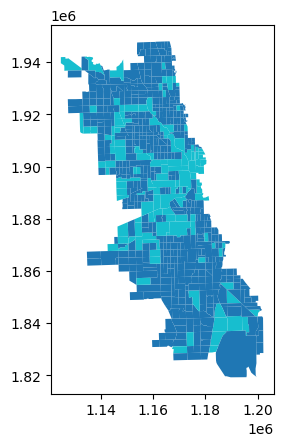

In [70]:
tracts[tracts['in_chi']].plot('big_tract')
plt.show()

/Users/eric/Repos/DNCTransit/.venv/lib/python3.9/site-packages/plotnine/stats/stat_bin.py:109: PlotnineWarning: 'stat_bin()' using 'bins = 18'. Pick better value with 'binwidth'.


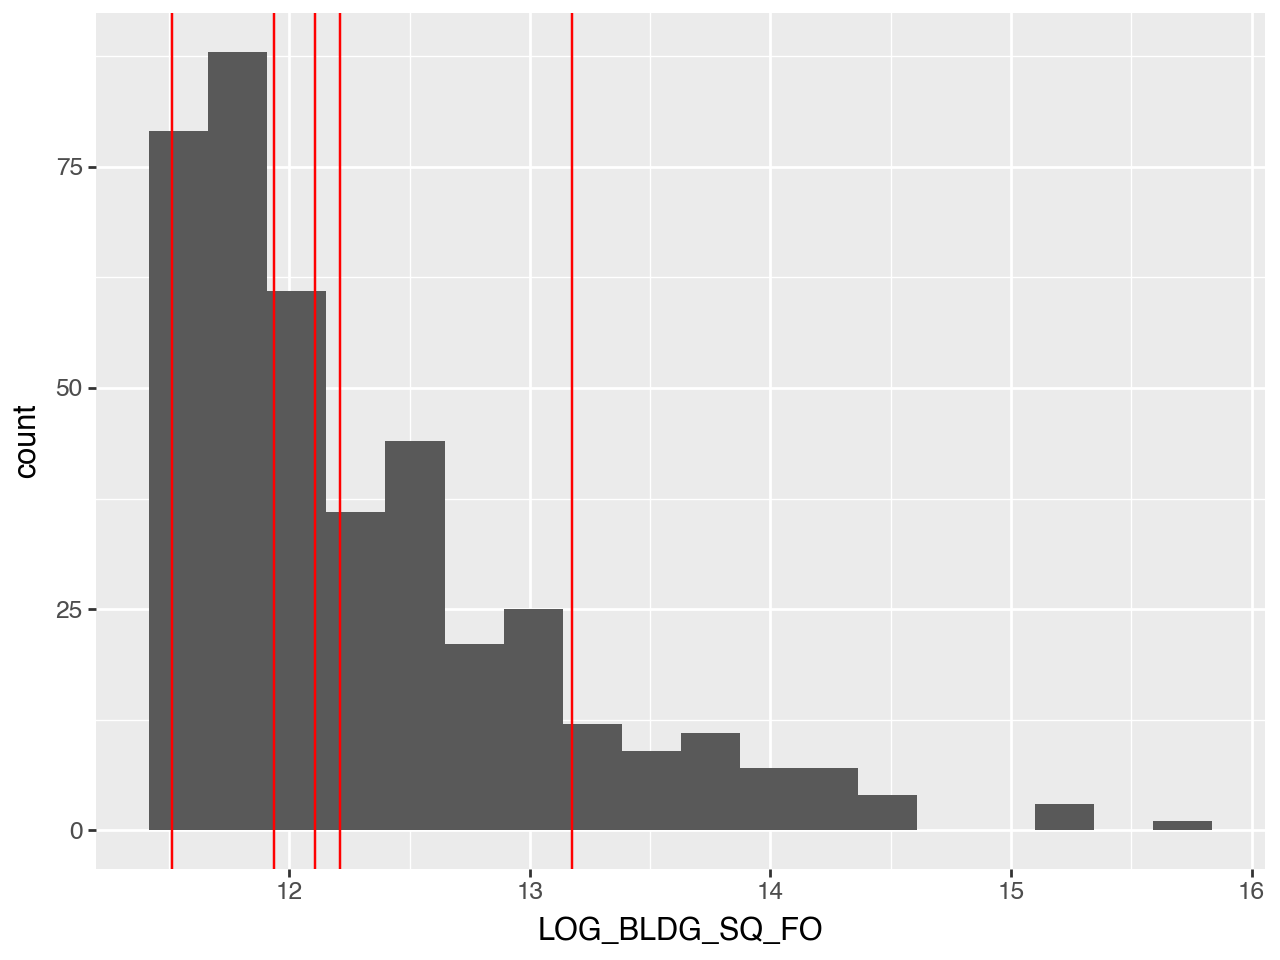

In [52]:
from plotnine import *
(ggplot(big_data, aes(x='LOG_BLDG_SQ_FO')) + geom_histogram() +
 geom_vline(aes(xintercept='POI_SQFT'), data=poi, color='red'))

0         0.0
1         0.0
2         0.0
3         0.0
4         0.0
         ... 
820601    0.0
820602    0.0
820603    0.0
820604    0.0
820605    0.0
Name: POI_SQFT, Length: 820606, dtype: float64